# Reproducibility Notebook — Multi-scale Percolation of Football Passing Networks

This notebook reproduces all key numbers and figures reported in the paper. Each cell corresponds to a specific section and can be run independently after Cell 1 (data loading).

**Environment**: Python 3.10+ with pandas, numpy, scipy, matplotlib, seaborn, pingouin, statsmodels, sklearn
---

**Revision update (July 2026).** The revised manuscript uses an updated percolation protocol: **100 Monte Carlo trials at all four scales** (previously 20 for L2 and 5 for L0/L1/L3), with the susceptibility curves averaged pointwise across trials before locating the maximum, and a **peak-validity restriction** (the susceptibility argmax is taken only over removal fractions where P_inf(f) >= 5% of P_inf(0)); targeted attack remains a single deterministic trajectory. Two datasets are shipped:

- `data/match_summary.csv` — original submission protocol (kept unchanged for provenance);
- `data/match_summary_mc100_guarded.csv` — revised protocol (used by the revised manuscript).

Cells 2-9 below verify the **originally submitted analysis** from `match_summary.csv`; Cell 1c verifies the **revised-protocol headline numbers** from `match_summary_mc100_guarded.csv`. The revised supplementary analyses (Sections S7-S14) have dedicated scripts under `code/supplementary/`. Note the revised manuscript's figure numbering: Figure 1 is a workflow diagram (not a pipeline product) and the former Figures 1-8 are now Figures 2-9.


## Cell 1: Environment Check & Data Loading

In [1]:
import sys, platform
import pandas as pd
import numpy as np
import scipy
from scipy import stats
from pathlib import Path

print(f"Python: {sys.version}")
print(f"pandas: {pd.__version__}, numpy: {np.__version__}, scipy: {scipy.__version__}")

# Load main data
DATA_DIR = Path("data")
ms = pd.read_csv(DATA_DIR / "match_summary.csv")
print(f"\nmatch_summary.csv: {len(ms)} rows")
print(f"Scales: {sorted(ms['Scale'].unique())} — {len(ms)//4} matches per scale")
print(f"Leagues: {sorted(ms['League'].unique())}")
print(f"Seasons: {sorted(ms['Season'].unique())}")
print(f"Teams: {ms['Team'].nunique()}")

# L2 filtered subset (main analysis)
# Filter: SCGC ratio >= 30% AND random failure exhibits percolation behaviour (fc_Error_Strong > 0)
l2 = ms[(ms['Scale'] == 'L2') & (ms['SCGC_Ratio'] >= 0.3) & (ms['fc_Error_Strong'] > 0)].copy()
print(f"\nL2 filtered (SCGC>=30%, fc_Error>0): N = {len(l2)}")
print(f"  -> {len(l2)/4560*100:.1f}% of 4560 L2 matches")

Python: 3.12.7 | packaged by Anaconda, Inc. | (main, Oct  4 2024, 08:22:19) [Clang 14.0.6 ]
pandas: 2.2.2, numpy: 1.26.4, scipy: 1.13.1

match_summary.csv: 18240 rows
Scales: ['L0', 'L1', 'L2', 'L3'] — 4560 matches per scale
Leagues: ['La Liga', 'Premier League']
Seasons: ['2022/23', '2023/24', '2024/25']
Teams: 48

L2 filtered (SCGC>=30%, fc_Error>0): N = 4343
  -> 95.2% of 4560 L2 matches


## Cell 1c: Revised Protocol (July 2026) — Headline Numbers

Verifies the key numbers of the **revised manuscript** from `data/match_summary_mc100_guarded.csv` (100 trials at all scales, pointwise-averaged susceptibility, peak-validity restriction). Expected values: L2 valid N = 4,330; fc_Error = 0.604 (SD 0.138); fc_Attack = 0.420 (SD 0.141); 95.1% of matches more robust to random than targeted removal; directed MR benchmark at L2: 0.601 vs 0.601, Bias = -0.001, r = 0.809, MAE = 0.064.

In [ ]:
# Revised-protocol headline numbers (revised manuscript)
gd = pd.read_csv(DATA_DIR / "match_summary_mc100_guarded.csv")
print(f"match_summary_mc100_guarded.csv: {len(gd)} rows "
      f"(same 49 columns as match_summary.csv, dev-style fc column names pc_*, plus 5 audit columns)")

l2g = gd[(gd["Scale"] == "L2") & (gd["SCGC_Ratio"] >= 0.3) & (gd["pc_Error_Strong"] > 0)]
print(f"\nL2 valid set (SCGC>=30%, fc_Error>0): N = {len(l2g)}   (paper: 4,330)")
fe, fa = l2g["pc_Error_Strong"], l2g["pc_Attack_Strong"]
print(f"  fc_Error  = {fe.mean():.3f} (SD = {fe.std():.3f})   (paper: 0.604, SD 0.138)")
print(f"  fc_Attack = {fa.mean():.3f} (SD = {fa.std():.3f})   (paper: 0.420, SD 0.141)")
print(f"  % fc_Error > fc_Attack: {(fe > fa).mean()*100:.1f}%   (paper: 95.1%)")

# Directed MR benchmark, L2 row of Table 3 (theory-valid subset: mu11/mu > 2)
tv = gd[(gd["Scale"] == "L2") & (gd["pc_Theory"] > 0)]
bias = (tv["pc_Theory"] - tv["pc_Error_Strong"]).mean()
r = tv["pc_Theory"].corr(tv["pc_Error_Strong"])
mae = (tv["pc_Theory"] - tv["pc_Error_Strong"]).abs().mean()
print(f"\nDirected MR benchmark at L2 (N = {len(tv)} theory-valid):")
print(f"  theory {tv['pc_Theory'].mean():.3f} vs simulation {tv['pc_Error_Strong'].mean():.3f}"
      f"   (paper: 0.601 vs 0.601)")
print(f"  Bias = {bias:+.3f}, r = {r:.3f}, MAE = {mae:.3f}   (paper: -0.001 / 0.809 / 0.064)")

## Cell 1b: Core Methodology Demo — Network Construction & Percolation

This cell demonstrates the full pipeline on a **single match**: raw JSON → directed passing network → structural metrics → edge percolation simulation. This is the core methodology of the paper (§2).

**Requires**: Raw StatsBomb event JSON data. Set `DATA_ROOT` below. If unavailable, skip to Cell 2.

In [2]:
import networkx as nx
import matplotlib.pyplot as plt

# ── Configuration: Set StatsBomb data root directory ──
DATA_ROOT = Path("data/raw  # TODO: Set your local StatsBomb event data path")

# Add pipeline module path
sys.path.insert(0, str(Path("code/pipeline").resolve()))
from data_loader import safe_load_match_events, extract_passes, build_substitution_map, apply_substitution_map
from network_builder import ZonalNetworkBuilder, SCALE_CONFIGS
from robustness import (multi_trial_edge_removal, edge_removal_simulation,
                         find_critical_threshold, calculate_robustness_integral,
                         calculate_molloy_reed_threshold, calculate_metrics_directed)
from compute_directed_indicators import compute_directed_indicators

# ── Step 1: Load raw match events ──
# Man City vs Burnley, EPL 2023/24 Matchday 1
MATCH_FILE = DATA_ROOT / "2_281_2023_24" / "3892755_events.json"
MATCH_ID = 3892755
TEAM_NAME = "Manchester City"

events = safe_load_match_events(str(MATCH_FILE))
print(f"Step 1: Load match events → {len(events)} events")

# Identify team IDs
team_ids = {}
for ev in events:
    if ev.get('type', {}).get('id') == 35:  # Starting XI
        team_ids[ev['team']['name']] = ev['team']['id']
print(f"  Teams: {team_ids}")
TEAM_ID = team_ids[TEAM_NAME]

# ── Step 2: Extract passes + substitution inheritance ──
sub_map = build_substitution_map(events, TEAM_ID)
passes_raw = extract_passes(events, MATCH_ID, TEAM_ID)
passes = apply_substitution_map(passes_raw, sub_map)
print(f"\nStep 2: Extract passes → {len(passes)} successful open-play passes")
print(f"  Substitution mapping: {len(sub_map)} substitutions")
p0 = passes[0]
print(f"  Example pass: {p0['player_name']} → {p0['recipient_name']}")
print(f"            Position: ({p0['x_start']:.1f}, {p0['y_start']:.1f}) → ({p0['x_end']:.1f}, {p0['y_end']:.1f})")

# ── Step 3: Build multi-scale spatially-embedded directed passing networks ──
# Nodes = (player_ID, zone_ID), directed edges = passing relationships
# MultiDiGraph preserves all passes (n_edges=624); simple DiGraph deduplicates, edge count decreases with scale
builder = ZonalNetworkBuilder()
print(f"\nStep 3: Multi-scale network construction")
print(f"  {'Scale':5s} {'Zones':>6s} {'|V|':>5s} {'|E|':>5s} {'⟨k⟩':>6s} {'SCGC%':>6s}")
networks = {}
for scale in ['L0', 'L1', 'L2', 'L3']:
    G = builder.build_network(passes, scale=scale)
    net_stats = builder.get_network_stats(G)
    networks[scale] = (G, net_stats)
    nx_g, ny_g = SCALE_CONFIGS[scale]
    print(f"  {scale:5s} {nx_g*ny_g:6d} {net_stats['n_nodes']:5d} {net_stats['n_unique_edges']:5d} "
          f"{net_stats['avg_degree']:6.2f} {net_stats['largest_scc_ratio']:6.1%}")

Step 1: Load match events → 3852 events
  Teams: {'Burnley': 34, 'Manchester City': 36}

Step 2: Extract passes → 624 successful open-play passes
  Substitution mapping: 5 substitutions
  Example pass: Rico Lewis → Rodrigo Hernández Cascante
            Position: (55.7, 18.9) → (55.3, 25.0)

Step 3: Multi-scale network construction
  Scale  Zones   |V|   |E|    ⟨k⟩  SCGC%
  L0       384   686   620   0.90   0.6%
  L1        96   371   601   1.62  50.1%
  L2        24   158   522   3.30  74.7%
  L3         6    57   344   6.04  93.0%


In [ ]:
# ── Step 4: Compute directed structural indicators (L2 as example) ──
G_l2, stats_l2 = networks['L2']
indicators = compute_directed_indicators(nx.DiGraph(G_l2))
print("Step 4: Directed structural indicators (L2)")
for k, v in indicators.items():
    print(f"  {k:25s} = {v:.4f}")

# ── Step 5: Directed edge percolation simulation ──
G_simple = nx.DiGraph(G_l2)  # Convert to simple DiGraph
print(f"\nStep 5: Edge percolation simulation (L2, |V|={G_simple.number_of_nodes()}, |E|={G_simple.number_of_edges()})")

# Error (random removal, averaged over 20 MC trials)
sim_error = multi_trial_edge_removal(G_simple, method='error', n_steps=50, n_trials=100)
fc_error, chi_error = find_critical_threshold(sim_error, 'strong')
R_error = calculate_robustness_integral(sim_error, 'strong')

# Attack (targeted removal, deterministic)
sim_attack = edge_removal_simulation(G_simple, method='attack', n_steps=50)
fc_attack, chi_attack = find_critical_threshold(sim_attack, 'strong')
R_attack = calculate_robustness_integral(sim_attack, 'strong')

# MR theoretical threshold
fc_mr = calculate_molloy_reed_threshold(G_simple)

print(f"  Error:  fc = {fc_error:.3f}, R = {R_error:.3f}, chi_max = {chi_error:.2f}")
print(f"  Attack: fc = {fc_attack:.3f}, R = {R_attack:.3f}, chi_max = {chi_attack:.2f}")
print(f"  MR theory: fc = {fc_mr:.3f}")
print(f"  RAI = (fc_Error - fc_Attack) / fc_Error = {(fc_error - fc_attack)/fc_error:.3f}")

# ── Step 6: Cross-check against pre-computed values in match_summary.csv ──
row = ms[(ms['MatchID'] == MATCH_ID) & (ms['Team'] == TEAM_NAME) & (ms['Scale'] == 'L2')]
if len(row) == 1:
    row = row.iloc[0]
    print(f"\nStep 6: Cross-check against pre-computed values (match_summary.csv)")
    print(f"  {'Metric':20s} {'Computed':>10s} {'Stored':>10s} {'Diff':>10s}")
    for label, computed, stored_col in [
        ('fc_Error', fc_error, 'fc_Error_Strong'),
        ('fc_Attack', fc_attack, 'fc_Attack_Strong'),
        ('fc_MR', fc_mr, 'fc_dMR'),
        ('R_Error', R_error, 'R_Error_Strong'),
        ('R_Attack', R_attack, 'R_Attack_Strong'),
    ]:
        stored = row[stored_col]
        diff = computed - stored
        print(f"  {label:20s} {computed:10.4f} {stored:10.4f} {diff:+10.4f}")
    print("\n  NOTE: Minor differences in Error mode are expected due to random seeds (MC averaging)")
else:
    print(f"\n  WARNING: Match record not found in match_summary.csv")

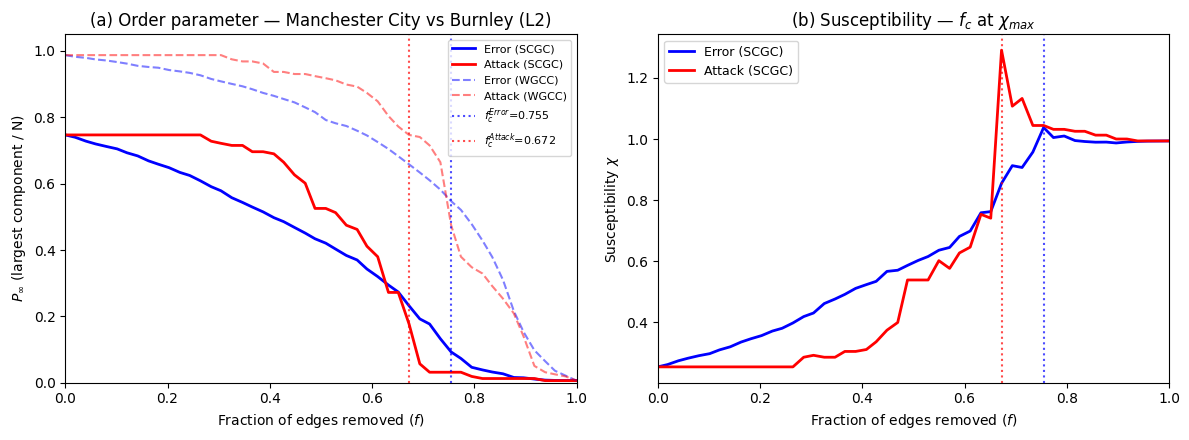

Blue dashed line = fc_Error (random failure threshold), Red dashed line = fc_Attack (targeted attack threshold)
Attack curve collapses earlier (smaller fc) → network more fragile under targeted attack → 'robust yet fragile'


In [4]:
# ── Step 7: Visualise percolation curves ──
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# (a) P_inf (order parameter) decay curve
ax = axes[0]
ax.plot(sim_error['f'], sim_error['P_inf_strong'], 'b-', lw=2, label='Error (SCGC)')
ax.plot(sim_attack['f'], sim_attack['P_inf_strong'], 'r-', lw=2, label='Attack (SCGC)')
ax.plot(sim_error['f'], sim_error['P_inf_weak'], 'b--', lw=1.5, alpha=0.5, label='Error (WGCC)')
ax.plot(sim_attack['f'], sim_attack['P_inf_weak'], 'r--', lw=1.5, alpha=0.5, label='Attack (WGCC)')
ax.axvline(fc_error, color='b', ls=':', alpha=0.7, label=f'$f_c^{{Error}}$={fc_error:.3f}')
ax.axvline(fc_attack, color='r', ls=':', alpha=0.7, label=f'$f_c^{{Attack}}$={fc_attack:.3f}')
ax.set_xlabel('Fraction of edges removed ($f$)')
ax.set_ylabel('$P_\\infty$ (largest component / N)')
ax.set_title(f'(a) Order parameter — {TEAM_NAME} vs Burnley (L2)')
ax.legend(fontsize=8, loc='upper right')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)

# (b) Chi (susceptibility) — percolation transition location
ax = axes[1]
ax.plot(sim_error['f'], sim_error['Chi_strong'], 'b-', lw=2, label='Error (SCGC)')
ax.plot(sim_attack['f'], sim_attack['Chi_strong'], 'r-', lw=2, label='Attack (SCGC)')
ax.axvline(fc_error, color='b', ls=':', alpha=0.7)
ax.axvline(fc_attack, color='r', ls=':', alpha=0.7)
ax.set_xlabel('Fraction of edges removed ($f$)')
ax.set_ylabel('Susceptibility $\\chi$')
ax.set_title('(b) Susceptibility — $f_c$ at $\\chi_{max}$')
ax.legend(fontsize=9)
ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()
print(f"Blue dashed line = fc_Error (random failure threshold), Red dashed line = fc_Attack (targeted attack threshold)")
print(f"Attack curve collapses earlier (smaller fc) → network more fragile under targeted attack → 'robust yet fragile'")

## Cell 2: §3.1 Percolation Robustness — Core Numbers

Originally submitted analysis (from `match_summary.csv`, original protocol): fc_Error = 0.599, fc_Attack = 0.423, 91.6% satisfy fc_Error > fc_Attack, r = 0.641. The revised manuscript reports the revised-protocol values (fc_Error = 0.604, fc_Attack = 0.420, 95.1%); see Cell 1c.

In [5]:
# §3.1 core numbers
fc_err = l2['fc_Error_Strong']
fc_att = l2['fc_Attack_Strong']

print("§3.1 Percolation Robustness (L2, N={})".format(len(l2)))
print(f"  fc_Error  = {fc_err.mean():.3f} (SD = {fc_err.std():.3f})")
print(f"  fc_Attack = {fc_att.mean():.3f} (SD = {fc_att.std():.3f})")
print(f"  % fc_Error > fc_Attack: {(fc_err > fc_att).mean()*100:.1f}%")

r, p = stats.pearsonr(fc_err, fc_att)
print(f"  Pearson r = {r:.3f}, P = {p:.2e}")

print(f"  CV_Error  = {fc_err.std()/fc_err.mean():.3f}")
print(f"  CV_Attack = {fc_att.std()/fc_att.mean():.3f}")

# Multi-scale Δfc
print("\nMulti-scale Δfc (all L, no filter):")
for scale in ['L0', 'L1', 'L2', 'L3']:
    sub = ms[ms['Scale'] == scale]
    e = sub['fc_Error_Strong'].mean()
    a = sub['fc_Attack_Strong'].mean()
    print(f"  {scale}: fc_Error={e:.3f}, fc_Attack={a:.3f}, Δ={e-a:.3f}, ratio={e/a:.2f}x" if a > 0 else f"  {scale}: fc_Error={e:.3f}, fc_Attack={a:.3f}")

§3.1 Percolation Robustness (L2, N=4343)
  fc_Error  = 0.599 (SD = 0.159)
  fc_Attack = 0.423 (SD = 0.145)
  % fc_Error > fc_Attack: 91.6%
  Pearson r = 0.641, P = 0.00e+00
  CV_Error  = 0.266
  CV_Attack = 0.342

Multi-scale Δfc (all L, no filter):
  L0: fc_Error=0.103, fc_Attack=0.024, Δ=0.080, ratio=4.39x
  L1: fc_Error=0.216, fc_Attack=0.115, Δ=0.101, ratio=1.88x
  L2: fc_Error=0.578, fc_Attack=0.408, Δ=0.170, ratio=1.42x
  L3: fc_Error=0.790, fc_Attack=0.613, Δ=0.177, ratio=1.29x


## Cell 3: §3.2 OLS Regression (Table 2)

Originally submitted analysis (original protocol): R² = 0.632, FlowHierarchy β = −0.400, μ₁₁/μ β = +0.464. The revised manuscript reports the revised-protocol regression (N = 4,330: R² = 0.662, FlowHierarchy β = −0.398, μ₁₁/μ β = +0.460).

In [6]:
import statsmodels.api as sm

METRICS = ['AvgDegree', 'Clustering', 'Assortativity', 'Reciprocity',
           'FlowHierarchy', 'OutDegreeCV', 'Mu11_Mu', 'CyclicTriadFraction']
LABELS = ['⟨k⟩', 'C', 'r', 'ρ↔', 'h', 'CV_out', 'μ₁₁/μ', 'f_cyc']
y_col = 'fc_Attack_Strong'

# Bivariate correlations
print("§3.2 Bivariate Pearson r with fc_Attack (L2, N={})".format(len(l2)))
for m, lab in zip(METRICS, LABELS):
    r, p = stats.pearsonr(l2[m], l2[y_col])
    print(f"  {lab:8s}: r = {r:+.3f}, P = {p:.2e}")

# Partial correlations
print("\nPartial correlations (controlling other 7):")
from sklearn.linear_model import LinearRegression
for i, (m, lab) in enumerate(zip(METRICS, LABELS)):
    controls = [x for x in METRICS if x != m]
    X_ctrl = l2[controls].values
    reg_x = LinearRegression().fit(X_ctrl, l2[m].values)
    res_x = l2[m].values - reg_x.predict(X_ctrl)
    reg_y = LinearRegression().fit(X_ctrl, l2[y_col].values)
    res_y = l2[y_col].values - reg_y.predict(X_ctrl)
    r, p = stats.pearsonr(res_x, res_y)
    print(f"  {lab:8s}: partial r = {r:+.3f}, P = {p:.2e}")

# OLS regression (standardised)
print("\nOLS Multiple Regression (standardised coefficients):")
X = l2[METRICS].copy()
X = (X - X.mean()) / X.std()
y = (l2[y_col] - l2[y_col].mean()) / l2[y_col].std()
X_const = sm.add_constant(X)
model = sm.OLS(y, X_const).fit(cov_type='cluster', cov_kwds={'groups': l2['Team']})
print(f"  R² = {model.rsquared:.3f}")
print(f"  {'Metric':18s} {'β':>8s} {'P':>10s}")
for m, lab in zip(METRICS, LABELS):
    print(f"  {lab:18s} {model.params[m]:+8.3f} {model.pvalues[m]:10.3f}")

§3.2 Bivariate Pearson r with fc_Attack (L2, N=4343)
  ⟨k⟩     : r = +0.765, P = 0.00e+00
  C       : r = +0.648, P = 0.00e+00
  r       : r = +0.092, P = 1.15e-09
  ρ↔      : r = +0.610, P = 0.00e+00
  h       : r = -0.750, P = 0.00e+00
  CV_out  : r = +0.232, P = 6.14e-54
  μ₁₁/μ   : r = +0.763, P = 0.00e+00
  f_cyc   : r = +0.562, P = 0.00e+00

Partial correlations (controlling other 7):
  ⟨k⟩     : partial r = +0.027, P = 7.65e-02
  C       : partial r = -0.045, P = 3.00e-03
  r       : partial r = +0.035, P = 1.96e-02
  ρ↔      : partial r = -0.078, P = 2.94e-07
  h       : partial r = -0.300, P = 3.42e-91
  CV_out  : partial r = +0.033, P = 2.87e-02
  μ₁₁/μ   : partial r = +0.100, P = 3.66e-11
  f_cyc   : partial r = -0.027, P = 7.22e-02

OLS Multiple Regression (standardised coefficients):
  R² = 0.632
  Metric                    β          P
  ⟨k⟩                  +0.113      0.092
  C                    -0.065      0.004
  r                    +0.024      0.029
  ρ↔           

## Cell 4: §3.3 Directed Molloy-Reed Benchmark (Table 3)

Originally submitted analysis (original protocol): L2 Bias = +0.003, r = 0.751, 95% valid; corr(k_in, k_out) by scale. The revised manuscript reports the revised-protocol benchmark (L2 Bias = -0.001, r = 0.809, MAE = 0.064); see Cell 1c.

In [7]:
# §3.3 MR theory benchmark
print("§3.3 Directed Molloy-Reed vs Simulation (Table 3)")
print(f"{'Scale':5s} {'N_valid':>10s} {'%':>5s} {'fc_dMR':>8s} {'fc_Error':>8s} {'Bias':>8s} {'MAE':>8s} {'r':>6s}")

for scale in ['L0', 'L1', 'L2', 'L3']:
    sub = ms[ms['Scale'] == scale].copy()
    valid = sub[sub['fc_dMR'] > 0]
    n_valid = len(valid)
    pct = n_valid / len(sub) * 100
    if n_valid > 1:
        mr_mean = valid['fc_dMR'].mean()
        err_mean = valid['fc_Error_Strong'].mean()
        bias = (valid['fc_dMR'] - valid['fc_Error_Strong']).mean()
        mae = (valid['fc_dMR'] - valid['fc_Error_Strong']).abs().mean()
        r, _ = stats.pearsonr(valid['fc_dMR'], valid['fc_Error_Strong'])
        print(f"{scale:5s} {n_valid:>10d} {pct:5.1f} {mr_mean:8.3f} {err_mean:8.3f} {bias:+8.3f} {mae:8.3f} {r:6.3f}")
    else:
        print(f"{scale:5s} {n_valid:>10d} {pct:5.1f}  — no valid MR predictions —")

# NOTE: corr(k_in, k_out) per scale (paper §3.3) is a within-network node-level
# statistic (Pearson r between each node's in-degree and out-degree).
# This requires raw network degree sequences, not available in match_summary.csv.
# Paper values: L0=-0.110, L1=0.447, L2=0.747, L3=0.809.
print("\nNOTE: corr(k_in, k_out) per scale requires raw network data (not in CSV).")
print("Paper values: L0=-0.110, L1=0.447, L2=0.747, L3=0.809")

§3.3 Directed Molloy-Reed vs Simulation (Table 3)
Scale    N_valid     %   fc_dMR fc_Error     Bias      MAE      r
L0             0   0.0  — no valid MR predictions —
L1          1305  28.6    0.259    0.396   -0.136    0.167  0.528
L2          4325  94.8    0.601    0.598   +0.003    0.080  0.751
L3          4554  99.9    0.794    0.790   +0.004    0.084  0.590

NOTE: corr(k_in, k_out) per scale requires raw network data (not in CSV).
Paper values: L0=-0.110, L1=0.447, L2=0.747, L3=0.809


## Cell 5: §3.4 RAI Comparison with Synthetic Models

Originally submitted analysis (original protocol): Football RAI = 0.30, BA RAI = 0.32, all 48 teams RAI positive [0.209, 0.398]. The revised manuscript reports revised-protocol values (soccer RAI = 0.31 +/- 0.05 across teams, BA 0.37, ER 0.25), computed from `data/synthetic_mc100_guarded.csv` and the revised empirical dataset.

In [8]:
# §3.4 RAI (Robustness-Attack Imbalance)
# Football teams (L2 filtered, team-level means)
ta = l2.groupby(['Team', 'League']).agg(
    fc_E=('fc_Error_Strong', 'mean'),
    fc_A=('fc_Attack_Strong', 'mean')
).reset_index()
ta['RAI'] = (ta['fc_E'] - ta['fc_A']) / ta['fc_E']

# RAI using method A (ratio of means)
rai_football = (ta['fc_E'].mean() - ta['fc_A'].mean()) / ta['fc_E'].mean()
print(f"§3.4 Football RAI (ratio of means) = {rai_football:.2f}")
print(f"  RAI range: [{ta['RAI'].min():.3f}, {ta['RAI'].max():.3f}]")
print(f"  All positive: {(ta['RAI'] > 0).all()}")
print(f"  RAI mean ± SD: {ta['RAI'].mean():.2f} ± {ta['RAI'].std():.2f}")

# Lowest and highest RAI teams
print(f"\n  Lowest RAI:  {ta.nsmallest(3, 'RAI')[['Team', 'RAI']].to_string(index=False)}")
print(f"  Highest RAI: {ta.nlargest(3, 'RAI')[['Team', 'RAI']].to_string(index=False)}")

# Synthetic baselines
syn = pd.read_csv(DATA_DIR / "synthetic_baselines.csv")
syn_cols = {'fc_Error': 'fc_Error_Strong', 'fc_Attack': 'fc_Attack_Strong'}
syn.rename(columns={k: v for k, v in syn_cols.items() if k in syn.columns}, inplace=True)
syn = syn[(syn['fc_Error_Strong'] > 0) & (syn['fc_Attack_Strong'] > 0)]

print("\nSynthetic model RAI:")
for model in syn['Model'].unique():
    s = syn[syn['Model'] == model]
    rai = (s['fc_Error_Strong'].mean() - s['fc_Attack_Strong'].mean()) / s['fc_Error_Strong'].mean()
    print(f"  {model:5s}: RAI = {rai:.2f}, fc_Error = {s['fc_Error_Strong'].mean():.2f}, fc_Attack = {s['fc_Attack_Strong'].mean():.2f}")

§3.4 Football RAI (ratio of means) = 0.30
  RAI range: [0.209, 0.398]
  All positive: True
  RAI mean ± SD: 0.30 ± 0.05

  Lowest RAI:               Team      RAI
      Real Madrid 0.208709
  Manchester City 0.219081
Manchester United 0.232183
  Highest RAI:     Team      RAI
 Granada 0.397511
Espanyol 0.395554
 Leganés 0.377738

Synthetic model RAI:
  ER   : RAI = 0.18, fc_Error = 0.45, fc_Attack = 0.37
  BA   : RAI = 0.32, fc_Error = 0.57, fc_Attack = 0.39
  WS   : RAI = 0.21, fc_Error = 0.13, fc_Attack = 0.10
  RGG  : RAI = -0.08, fc_Error = 0.37, fc_Attack = 0.40


## Cell 6: §3.5 Team Stability — ICC, Home/Away, Cross-League

Originally submitted analysis (original protocol): ICC(3,1) = 0.812, home > away Δ ≈ 1-3%, r = 0.80-0.89; EPL ≈ La Liga on fc_Attack. The revised manuscript reports the revised-protocol values (cross-season ICC(3,1) = 0.829; home-away r = 0.81-0.89; home advantage 1-3 percentage points).

In [9]:
import pingouin as pg

FC = 'fc_Attack_Strong'

# Team-season means
ts = l2.groupby(['Team', 'Season', 'League'])[FC].mean().reset_index()
seasons = sorted(ts['Season'].unique())

# ICC: teams appearing in all 3 seasons
team_counts = ts.groupby('Team')['Season'].nunique()
common_teams = team_counts[team_counts == 3].index.tolist()
ts_common = ts[ts['Team'].isin(common_teams)].copy()
print(f"§3.5 Cross-season ICC ({len(common_teams)} teams × 3 seasons)")
icc_df = pg.intraclass_corr(data=ts_common, targets='Team', raters='Season', ratings=FC)
# ICC3 = ICC(3,1) single measures; ICC3k = ICC(3,k) average measures
icc31 = icc_df[icc_df['Type'] == 'ICC3']['ICC'].values[0]
print(f"  ICC(3,1) = {icc31:.3f}")

# Home vs Away
print(f"\nHome vs Away comparison:")
for season in seasons:
    sub = l2[l2['Season'] == season]
    ha = sub.groupby(['Team', 'Venue'])[FC].mean().reset_index()
    home = ha[ha['Venue'] == 'Home'].set_index('Team')[FC]
    away = ha[ha['Venue'] == 'Away'].set_index('Team')[FC]
    common = home.index.intersection(away.index)
    r, p_r = stats.pearsonr(home[common], away[common])
    t, p_t = stats.ttest_rel(home[common], away[common])
    delta = (home[common] - away[common]).mean()
    print(f"  {season}: r={r:.2f}, Δ(H-A)={delta:.3f}, paired t P={p_t:.3f}, N={len(common)}")

# EPL vs La Liga — fc_Attack (Fig 7g)
print(f"\nEPL vs La Liga — fc_Attack (Fig 7g):")
epl_fc = l2[l2['League'] == 'Premier League'][FC]
liga_fc = l2[l2['League'] == 'La Liga'][FC]
t, p = stats.ttest_ind(epl_fc, liga_fc, equal_var=False)
d = (epl_fc.mean() - liga_fc.mean()) / np.sqrt((epl_fc.std()**2 + liga_fc.std()**2) / 2)
print(f"  EPL: {epl_fc.mean():.3f}, La Liga: {liga_fc.mean():.3f}")
print(f"  Welch t P = {p:.3f}, Cohen's d = {d:.2f}")

# EPL vs La Liga — Reciprocity (Fig 7h)
print(f"\nEPL vs La Liga — Reciprocity (Fig 7h):")
epl_rec = l2[l2['League'] == 'Premier League']['Reciprocity']
liga_rec = l2[l2['League'] == 'La Liga']['Reciprocity']
t, p = stats.ttest_ind(epl_rec, liga_rec, equal_var=False)
d = (epl_rec.mean() - liga_rec.mean()) / np.sqrt((epl_rec.std()**2 + liga_rec.std()**2) / 2)
print(f"  EPL: {epl_rec.mean():.3f}, La Liga: {liga_rec.mean():.3f}")
print(f"  Welch t P = {p:.4f}, Cohen's d = {d:.2f}")

§3.5 Cross-season ICC (32 teams × 3 seasons)
  ICC(3,1) = 0.812

Home vs Away comparison:
  2022/23: r=0.80, Δ(H-A)=0.015, paired t P=0.033, N=40
  2023/24: r=0.89, Δ(H-A)=0.029, paired t P=0.000, N=40
  2024/25: r=0.86, Δ(H-A)=0.012, paired t P=0.036, N=40

EPL vs La Liga — fc_Attack (Fig 7g):
  EPL: 0.424, La Liga: 0.422
  Welch t P = 0.626, Cohen's d = 0.01

EPL vs La Liga — Reciprocity (Fig 7h):
  EPL: 0.220, La Liga: 0.211
  Welch t P = 0.0000, Cohen's d = 0.15


## Cell 7: §3.5 Cross-Sectional Validation (Table 4)

Paper values (Table 4; unchanged in the revision): Spearman ρ = 0.132–0.189, partial ρ = 0.148–0.227. The originally submitted analysis additionally reported within-team ρ = 0.212–0.258.

In [10]:
# §3.5 Cross-sectional validation — calls the standalone script
import subprocess
result = subprocess.run(
    [sys.executable, "code/cross_sectional_validation.py"],
    capture_output=True, text=True
)
print(result.stdout)
if result.stderr:
    print("STDERR:", result.stderr[:500])

Table 4: Cross-sectional association (per-season, Spearman rho)

2022/23:
  n = 902
  Spearman rho = 0.178, P = 7.88e-08
  Partial rho = 0.227, P = 5.84e-12 (n_valid=902)

2023/24:
  n = 920
  Spearman rho = 0.189, P = 7.51e-09
  Partial rho = 0.208, P = 2.03e-10 (n_valid=920)

2024/25:
  n = 846
  Spearman rho = 0.132, P = 1.23e-04
  Partial rho = 0.148, P = 1.49e-05 (n_valid=846)

Within-team rank analysis

2022/23 (40 teams):
  Within-team residual vs value: avg rho = 0.256, P = 9.98e-13
  Within-team pass volume vs value: avg rho = 0.224

2023/24 (40 teams):
  Within-team residual vs value: avg rho = 0.258, P = 1.07e-08
  Within-team pass volume vs value: avg rho = 0.210

2024/25 (40 teams):
  Within-team residual vs value: avg rho = 0.212, P = 6.17e-06
  Within-team pass volume vs value: avg rho = 0.146

High-residual vs neutral group value comparison

2022/23:
  High residual (z>1s): n=165, median=EUR15.0M
  Neutral (|z|<0.5s): n=334, median=EUR8.0M
  Ratio: 1.9x, P = 2.06e-06

2

## Cell 8: Supplementary Material Verification

S5 threshold sensitivity (Table S4) and S6 SCGC vs WGCC (Table S5)

In [11]:
# S5: Threshold sensitivity
print("=" * 60)
print("S5: SCGC Threshold Sensitivity (Table S4)")
print("=" * 60)
result = subprocess.run([sys.executable, "code/threshold_sensitivity.py"], capture_output=True, text=True)
print(result.stdout)

# S6: SCGC vs WGCC
print("\n" + "=" * 60)
print("S6: SCGC vs WGCC (Table S5)")
print("=" * 60)
result = subprocess.run([sys.executable, "code/scgc_vs_wgcc.py"], capture_output=True, text=True)
print(result.stdout)

S5: SCGC Threshold Sensitivity (Table S4)
Total L2 matches: 4560

Table S4a — Bivariate Pearson r between structural metrics and fc_Attack_Strong
Metric                 ≥0%            ≥10%            ≥20%            ≥30%            ≥40%            ≥50%
------------------------------------------------------------------------------------------
N                     4452            4446            4410            4343            4132            3626
------------------------------------------------------------------------------------------
⟨k⟩              +0.784***       +0.783***       +0.776***       +0.765***       +0.737***       +0.685***
C                +0.671***       +0.669***       +0.661***       +0.648***       +0.615***       +0.556***
r                +0.096***       +0.095***       +0.090***       +0.092***       +0.087***       +0.091***
ρ↔               +0.641***       +0.639***       +0.625***       +0.610***       +0.572***       +0.502***
h                -0.762***    

## Cell 9: Generate All Figures

Calls each figure script. Output is written to a `figures/` directory (created on demand; pre-generated figures are not shipped with the repository). Script outputs correspond to the revised manuscript's figure numbers: Figure 1 is the workflow diagram (not a pipeline product), and the scripts below produce Figures 2-9 and Supplementary Figures S1-S2.

Note: `fig_multiscale.py` (Fig 2) and `fig_baena_case.py` (Fig 9) require raw StatsBomb event JSON data and are skipped here.

In [ ]:
import os, time

SCRIPTS = [
    # fig_multiscale.py skipped (requires raw StatsBomb JSON, same as fig_baena_case)
    ("fig_error_vs_attack.py",   "Fig 3: Error vs Attack"),
    ("fig_structural_factors.py","Fig 4: Structural factors"),
    ("fig_partial_correlation.py","Fig 5: Partial correlation"),
    ("fig_mr_benchmark.py",      "Fig 6: MR benchmark"),
    ("fig_rai_scatter.py",       "Fig 7: RAI scatter"),
    ("fig_team_stability.py",    "Fig 8: Team stability"),
    # fig_baena_case.py skipped (requires raw StatsBomb JSON)
    ("fig_corr_heatmap.py",      "Fig S1: Correlation matrix"),
    ("fig_position_analysis.py", "Fig S2: Position analysis"),
]

print("Skipped: Fig 2 (fig_multiscale.py) — requires raw StatsBomb JSON")
print("Skipped: Fig 9 (fig_baena_case.py) — requires raw StatsBomb JSON")
print("(Figure numbers refer to the revised manuscript; Fig 1 is the workflow diagram.)\n")

for script, desc in SCRIPTS:
    t0 = time.time()
    result = subprocess.run(
        [sys.executable, f"code/{script}"],
        capture_output=True, text=True, timeout=120
    )
    elapsed = time.time() - t0
    status = "OK" if result.returncode == 0 else f"FAIL (rc={result.returncode})"
    print(f"  {desc:35s} [{status}] ({elapsed:.1f}s)")
    if result.returncode != 0:
        print(f"    STDERR: {result.stderr[:200]}")

print(f"\nAll figures in figures/:")
for f in (sorted(os.listdir("figures")) if os.path.isdir("figures") else []):
    if f.endswith('.png'):
        size_kb = os.path.getsize(f"figures/{f}") / 1024
        print(f"  {f} ({size_kb:.0f} KB)")